## settings that increases chances of infeasible/unbounded solution (status = 4):
1. large number of particles
2. small n_trades (larger bayesian uncertainty)
3. lower loss threshold (C_max)
## status = 4 is independent of the choice of the big M and chance threshold.

In [1]:
%load_ext autoreload
%autoreload 2
import pickle
import os
import arviz as az


import seaborn as sns
import matplotlib.pyplot as plt
from collections import defaultdict
import numpy as np
import pandas as pd
import scipy.stats as stats
from tqdm import tqdm


In [8]:
def get_str_inbetween(s, start, end):
    return (s.split(start))[1].split(end)[0]

def get_mip_info_multiple(base_dirs):
    # Combine data from multiple directories
    all_data = []
    if not isinstance(base_dirs, list):
        base_dirs = [base_dirs]
        
    for base_dir in base_dirs:
        df = get_mip_info(base_dir)
        df['base_dir'] = os.path.basename(base_dir)
        all_data.append(df)
    
    combined_df = pd.concat(all_data, ignore_index=True)
    return combined_df

def get_mip_info(base_dir):
    # Storage for all trade data
    # Initialize list to store data
    data_rows = []

    # Iterate through subfolders
    for subfolder in tqdm(os.listdir(base_dir)):
        subfolder_path = os.path.join(base_dir, subfolder)
        if os.path.isdir(subfolder_path):            
            # Iterate through files in subfolder
            for filename in os.listdir(subfolder_path):
                if filename.endswith('.pkl'):
                    file_path = os.path.join(subfolder_path, filename)
                    # print(f"  Reading file: {filename}")
                    
                    with open(file_path, 'rb') as f:
                        data = pickle.load(f)
                    
                    ntrades = int(filename.split('_')[2])
                    seed = filename.split('_')[-1].split('.')[0]
                    trades = np.array(data['trades'])
                    
                    # Extract key info from filename and subfolder
                    row ={
                        'subfolder': subfolder,
                        'filename': filename,
                        'status': data.get('status', 'unknown'),
                        'obj_val': data.get('obj_val', np.nan),
                        'runtime': data.get('runtime', np.nan),
                        'ntrades': ntrades,
                        'seed': seed,
                    }
                    
                    for j, trade in enumerate(trades):
                        row[f'trade_{j}'] = trade
                        
                    try:
                        ntrades = int(get_str_inbetween(subfolder, 'ntrades', '_'))
                        nscenarios = int(get_str_inbetween(subfolder, 'nscenarios', '_'))
                        lossThresh = float(get_str_inbetween(subfolder, 'lossThresh', '_'))
                        chanceThresh = float(get_str_inbetween(subfolder, 'chanceThresh', '_')) / 100
                        M = int(subfolder.split('M')[1])
                        row.update({
                            'ntrades': ntrades,
                            'nscenarios': nscenarios,
                            'lossThresh': lossThresh,
                            'chanceThresh': chanceThresh,
                            'M': M
                        })
                    except:
                        pass
                            

        data_rows.append(row)

    # Create DataFrame
    df = pd.DataFrame(data_rows)
    
    return df
        


In [ ]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results_20250830_thresh5_n1000',
             '/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh1_n1000',
             '/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh2_n1000',
             '/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh3_n1000',
             '/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh7_n1000',
             '/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh10_n1000']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    chanceThresh = int(base_dir.split('_thresh')[-1].split('_')[0])
    df = get_mip_info(base_dir)
    df['base_dir'] = os.path.basename(base_dir)
    df['threshold'] = chanceThresh/100
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 7/7 [00:00<00:00, 291.73it/s]


Processing subfolder: 20_nscenarios_1000
Processing subfolder: 1000_nscenarios_1000
Processing subfolder: 10_nscenarios_1000
Processing subfolder: 400_nscenarios_1000
Processing subfolder: 150_nscenarios_1000
Processing subfolder: 50_nscenarios_1000
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does n

100%|██████████| 5/5 [00:00<00:00, 254.93it/s]


Processing subfolder: 1000_nscenarios_1000
Processing subfolder: 400_nscenarios_1000
Processing subfolder: 150_nscenarios_1000
Processing subfolder: 50_nscenarios_1000
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does no

100%|██████████| 5/5 [00:00<00:00, 231.77it/s]


Processing subfolder: 1000_nscenarios_1000
Processing subfolder: 400_nscenarios_1000
Processing subfolder: 150_nscenarios_1000
Processing subfolder: 50_nscenarios_1000
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does no

... (2 outputs left out)

100%|██████████| 5/5 [00:00<00:00, 156.00it/s]


Processing subfolder: 1000_nscenarios_1000
Processing subfolder: 400_nscenarios_1000
Processing subfolder: 150_nscenarios_1000
Processing subfolder: 50_nscenarios_1000
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does no

100%|██████████| 6/6 [00:00<00:00, 226.63it/s]

Processing subfolder: 1000_nscenarios_1000
Processing subfolder: 400_nscenarios_1000
Processing subfolder: 50_nscenarios_10000
Processing subfolder: 150_nscenarios_1000
Processing subfolder: 50_nscenarios_1000
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int() with base 10: ''
Subfolder name does not contain info: invalid literal for int

In [29]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results_20250910']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 59/59 [00:00<00:00, 341.40it/s]


In [30]:
combined_df.columns

Index(['subfolder', 'filename', 'status', 'obj_val', 'runtime', 'ntrades',
       'seed', 'trade_0', 'trade_1', 'trade_2', 'trade_3', 'trade_4',
       'trade_5', 'trade_6', 'trade_7', 'trade_8', 'trade_9', 'trade_10',
       'nscenarios', 'lossThresh', 'chanceThresh', 'M'],
      dtype='object')

In [31]:
combined_df.ntrades.value_counts()

ntrades
400     16
50      15
150     15
1000    13
Name: count, dtype: int64

In [26]:
combined_df.groupby(['ntrades', 'lossThresh']).apply(lambda x: (x.status == 4).mean()).unstack().dropna()

/tmp/ipykernel_2224023/1486633444.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  combined_df.groupby(['ntrades', 'lossThresh']).apply(lambda x: (x.status == 4).mean()).unstack().dropna()


lossThresh,600000.0,700000.0,800000.0,900000.0,1000000.0
ntrades,,,,,
50,1.0,1.0,1.0,0.333333,0.0
150,1.0,1.0,1.0,0.000000,0.0
400,1.0,1.0,1.0,0.000000,0.0


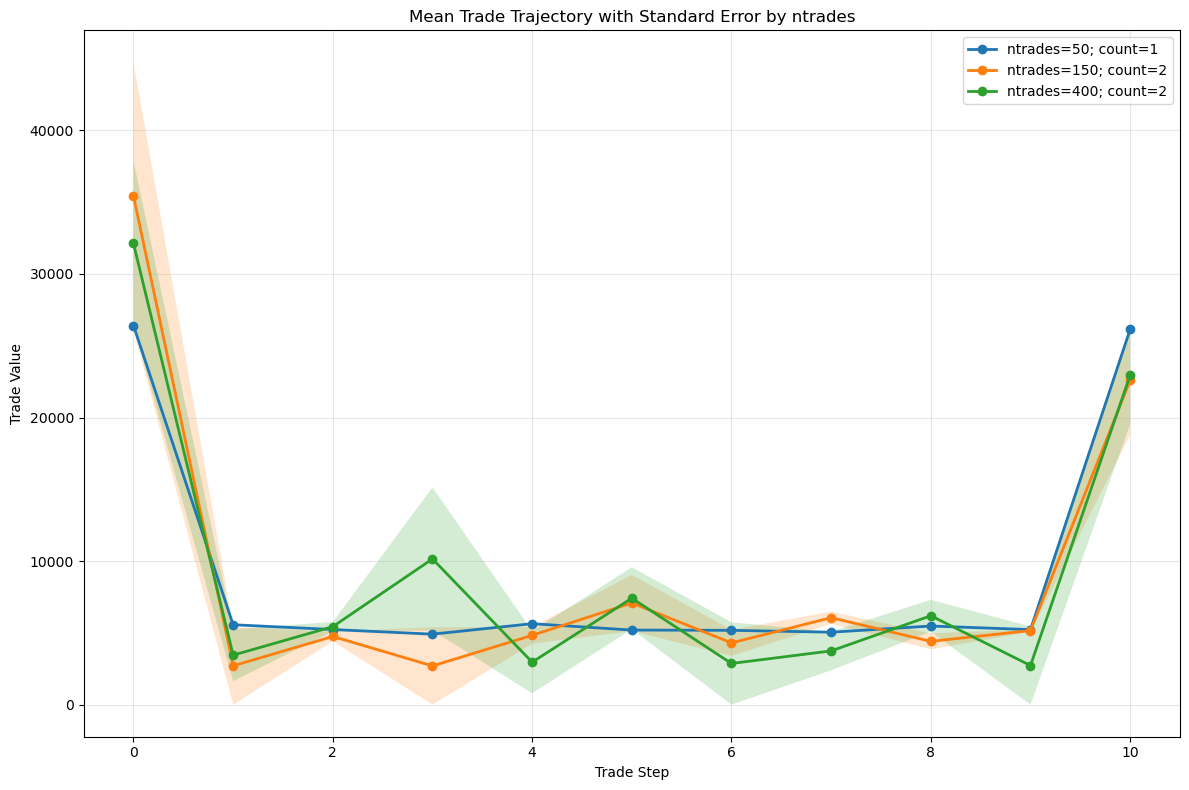

In [18]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success = combined_df[(combined_df['lossThresh'] >= 9e5) &
                         (combined_df['nscenarios'] == 3000) &
                         (combined_df['status'] == 2)]
ntrades_groups = df_success.groupby('ntrades')

plt.figure(figsize=(12, 8))

# Get unique ntrades values and sort them
ntrades_values = sorted(df_success['ntrades'].unique())[-3:]

for ntrades, group_data in df_success.groupby('ntrades'):

    # Calculate mean and standard error for each trade column
    means = []
    std_errors = []

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(11)  # Trade steps 0 to 10
    
    # Plot mean trajectory
    plt.plot(x, means, marker='o', label=f'ntrades={ntrades}; count={len(group_data)}', linewidth=2)
    
    # Add standard error bands
    plt.fill_between(x, means - std_errors, means + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Trade Value')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

/tmp/ipykernel_2122363/1798976096.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  combined_df.groupby('ntrades').apply(lambda x: (x.status == 4).mean()).plot(


<Axes: title={'center': 'Proportion of infeasible runs'}, xlabel='Number of Trades in training data'>

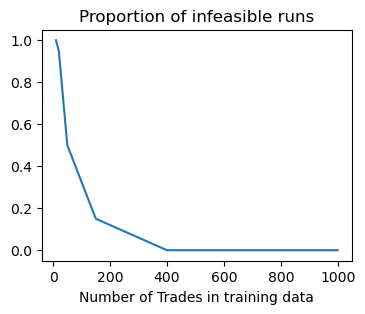

In [ ]:
# count the number of rows where status == 4
combined_df.groupby('ntrades').apply(lambda x: (x.status == 4).mean()).plot(
    title='Proportion of infeasible runs', xlabel='Number of Trades in training data',
    figsize=(4,3))

In [37]:
combined_df.groupby(['ntrades', 'threshold']).apply(lambda x: (x.status == 4).mean()).unstack().dropna()

/tmp/ipykernel_2122363/2004446834.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  combined_df.groupby(['ntrades', 'threshold']).apply(lambda x: (x.status == 4).mean()).unstack().dropna()


threshold,0.01,0.02,0.03,0.05,0.07,0.10
ntrades,,,,,,
50,0.50,0.50,0.50,0.50,0.50,0.50
150,0.15,0.15,0.15,0.15,0.15,0.15
400,0.00,0.00,0.00,0.00,0.00,0.00
1000,0.00,0.00,0.00,0.00,0.00,0.00


In [50]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh10_n1000',
             '/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh10_n2000',
             '/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh10_n5000']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    nscenarios = int(base_dir.split('_')[-1][1:])
    df = get_mip_info(base_dir)
    df['base_dir'] = os.path.basename(base_dir)
    df['nscenarios'] = nscenarios
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 6/6 [00:00<00:00, 519.84it/s]


Processing subfolder: 1000_nscenarios_1000
Processing subfolder: 400_nscenarios_1000
Processing subfolder: 50_nscenarios_10000
Processing subfolder: 150_nscenarios_1000
Processing subfolder: 50_nscenarios_1000


100%|██████████| 5/5 [00:00<00:00, 467.76it/s]


Processing subfolder: 1000_nscenarios_2000
Processing subfolder: 150_nscenarios_2000
Processing subfolder: 50_nscenarios_2000
Processing subfolder: 400_nscenarios_2000


100%|██████████| 5/5 [00:00<00:00, 281.94it/s]

Processing subfolder: 400_nscenarios_5000
Processing subfolder: 150_nscenarios_5000
Processing subfolder: 1000_nscenarios_5000
Processing subfolder: 50_nscenarios_5000


In [51]:
combined_df.groupby(['ntrades', 'nscenarios']).apply(lambda x: (x.status == 4).mean()).unstack().dropna()

/tmp/ipykernel_2122363/65865180.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  combined_df.groupby(['ntrades', 'nscenarios']).apply(lambda x: (x.status == 4).mean()).unstack().dropna()


nscenarios,1000,2000,5000
ntrades,,,
50,0.50,0.85,0.90
150,0.15,0.40,0.40
400,0.00,0.10,0.15
1000,0.00,0.05,0.05


In [ ]:
combined_df.groupby(['ntrades', 'nscenarios']).apply(lambda x: (x.status == 4).mean()).unstack().dropna()

/tmp/ipykernel_2122363/65865180.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  combined_df.groupby(['ntrades', 'nscenarios']).apply(lambda x: (x.status == 4).mean()).unstack().dropna()


nscenarios,1000,2000,5000
ntrades,,,
50,0.50,0.85,0.90
150,0.15,0.40,0.40
400,0.00,0.10,0.15
1000,0.00,0.05,0.05


In [ ]:

for chance_threshold in [0.03, 0.05, 0.07, 0.1]:
    print(f"Chance threshold: {chance_threshold}")
    if chance_threshold == 0.05:
        base_dir = '/nfs/home/dannis/AC-model/TIM_opt_results_20250830'
    else:
        base_dir = '/nfs/home/dannis/AC-model/TIM_opt_results_20250909_thresh' + str(int(chance_threshold*100))
    df_subset = df[df['ntrades'] == chance_threshold]
    print(df_subset.groupby('status').size())
    print(df_subset[['obj_val']].describe())
    print("\n")

In [19]:
import gurobipy as gp
env = gp.Env()
model = gp.read("../model.ilp", env=env)

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2625901
Academic license 2625901 - for non-commercial use only - registered to da___@stcatz.ox.ac.uk
Read LP format model from file ../model.ilp
Reading time = 0.00 seconds
: 1 rows, 12 columns, 11 nonzeros


In [22]:
for constr in model.getConstrs():
    coeffs = model.getRow(constr)
    for i in range(coeffs.size()):
        print(f"Unstable coefficient {coeffs.getCoeff(i)} in constraint {constr}")

Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>
Unstable coefficient 1.0 in constraint <gurobi.Constr TotalShares>


In [24]:
model.ObjVal

AttributeError: Unable to retrieve attribute 'ObjVal'